# Email Spam Detection with Machine Learning

## 1. Introduction

Spam detection is a Natural Language Processing (NLP) task that involves identifying unwanted or irrelevant messages.

In this project, machine learning techniques will be used to classify text messages into two categories: spam and ham.

- **Spam:** Unwanted messages, advertisements or potentially fraudulent messages.
- **Ham:** Normal and legitimate messages.

## Project Objective

The objective is to develop and evaluate machine learning classification models that can automatically distinguish spam messages from legitimate messages.

## Technologies and Libraries

- Python
- Pandas
- NumPy
- Scikit-learn
- NLTK
- Matplotlib
- Seaborn
- Jupyter Notebook

## Machine Learning Approach

The project will use Natural Language Processing techniques to clean and prepare text messages.

TF-IDF (Term Frequency-Inverse Document Frequency) will convert text into numerical features that machine learning algorithms can understand.

Two classification algorithms will be trained and compared:

1. Multinomial Naive Bayes
2. Logistic Regression

In [1]:
#Import pandas for loading and working with datasets
import pandas as pd

#Import numpy for numerical operations
import numpy as np

#Import matplotlib and seaborn for data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

#Import regular expressions for text cleaning
import re

#Import NLTK for natural language processing
import nltk
from nltk.corpus import stopwords

#Import TF-IDF for converting text into numerical features
from sklearn.feature_extraction.text import TfidfVectorizer

#Import train_test_split for splitting the dataset
from sklearn.model_selection import train_test_split

#Import the two machine learning classifiers
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

#Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

#Import WordCloud for optional word visualisations
from wordcloud import WordCloud

In [2]:
# Download the English stopwords dataset
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

## 2. Load and Inspect the Dataset

The dataset contains text messages labelled as either spam or ham. Before preparing the data for machine learning, we need to inspect its structure, identify its columns and check whether it contains missing values.

In [3]:
# Load the dataset using Latin-1 encoding
df = pd.read_csv("data/raw/spam.csv", encoding="latin-1")

#Display the number of rows and columns
print("Dataset shape:", df.shape)

#Display all column names
print("\nColumn names:")
print(df.columns.tolist())

#Display the first five rows
print("\nFirst five rows:")
display(df.head())

#Display information about the dataset
print("\nDataset information:")
df.info()

Dataset shape: (5572, 5)

Column names:
['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']

First five rows:


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


## 3. Data Cleaning

The dataset contains five columns, but only two are relevant to our project.

- `v1` contains the message category (spam or ham).
- `v2` contains the message text.

The remaining columns contain unnecessary information and mostly missing values. We will remove them and rename the relevant columns to make the dataset easier to understand.

In [4]:
#Keep only the two columns needed for spam classification
df = df[["v1", "v2"]].copy()

#Rename the columns to more descriptive names
df.columns = ["label", "message"]

#Display the cleaned dataset
display(df.head())

#Check the dataset dimensions
print("Cleaned dataset shape:", df.shape)

#Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

#Check for duplicate messages
print("\nDuplicate rows:", df.duplicated().sum())

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Cleaned dataset shape: (5572, 2)

Missing values:
label      0
message    0
dtype: int64

Duplicate rows: 403


In [5]:
#Remove duplicate messages from the dataset
df = df.drop_duplicates()

#Reset the row index after removing duplicates
df = df.reset_index(drop=True)

#Display the updated dataset size
print("Dataset shape after removing duplicates:", df.shape)

#Confirm that no duplicate rows remain
print("Remaining duplicates:", df.duplicated().sum())

Dataset shape after removing duplicates: (5169, 2)
Remaining duplicates: 0


## 4. Class Distribution Analysis

Class distribution analysis helps us understand how many messages belong to each category.

Our dataset contains two categories:

- **Ham:** Legitimate messages.
- **Spam:** Unwanted or suspicious messages.

We will calculate the number and percentage of messages in each category and visualise the results using a bar chart.

This analysis is important because an imbalanced dataset can affect how well a machine learning model identifies each category.

Message counts:
label
ham     4516
spam     653
Name: count, dtype: int64

Message percentages:
label
ham     87.37
spam    12.63
Name: proportion, dtype: float64


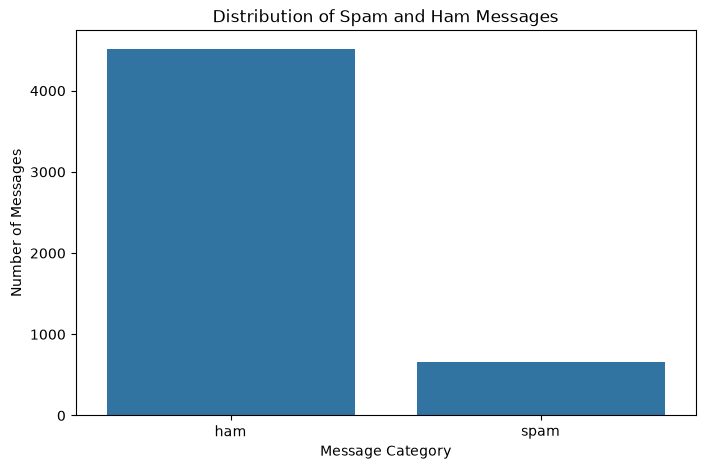

In [6]:
#Count the number of messages in each category
label_counts = df["label"].value_counts()

#Calculate the percentage of each category
label_percentages = df["label"].value_counts(normalize=True) * 100

#Display the number of messages
print("Message counts:")
print(label_counts)

#Display the percentages
print("\nMessage percentages:")
print(label_percentages.round(2))

#Create a bar chart showing the class distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="label")

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.show()

## 5. Text Preprocessing

Text preprocessing is the process of cleaning text data before using it to train a machine learning model.

Messages often contain uppercase letters, punctuation and common words that may not provide much useful information.

We will perform the following steps:

1. Convert all text to lowercase.
2. Remove punctuation and numbers.
3. Remove common English stopwords such as "the", "is", "and" and "a".
4. Store the cleaned messages in a new column called `clean_message`.

These steps help standardise the text and reduce unnecessary information.

In [7]:
#Get the English stopwords from NLTK
stop_words = set(stopwords.words("english"))

#Create a function to clean individual messages
def clean_text(text):

    #Convert the message to lowercase
    text = text.lower()

    #Remove punctuation and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    #Split the message into individual words
    words = text.split()

    #Remove common English stopwords
    words = [word for word in words if word not in stop_words]

    #Join the remaining words into a sentence
    return " ".join(words)


#Apply the cleaning function to every message
df["clean_message"] = df["message"].apply(clean_text)

#Display original and cleaned messages
display(df[["message", "clean_message"]].head())

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goes usf lives around though


## 6. Feature Extraction Using TF-IDF

Machine learning algorithms cannot directly understand text messages. Therefore, we need to convert the cleaned messages into numerical features.

We will use **TF-IDF (Term Frequency-Inverse Document Frequency)**.

TF-IDF measures how important a word is within a message compared with how frequently it appears across all messages.

It considers two factors:

1. **Term Frequency (TF):** Measures how often a word appears in a particular message.
2. **Inverse Document Frequency (IDF):** Reduces the importance of words that appear in many messages and gives more importance to words that are less common across the dataset.

For example, words such as "the" and "is" appear frequently and are usually less informative. Words such as "prize", "winner" and "claim" may be more useful when identifying spam.

TF-IDF converts messages into numerical vectors that machine learning models can use for classification.

In [8]:
#Separate the cleaned messages from their labels
X = df["clean_message"]

#Store the message categories
y = df["label"]

#Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

#Display the sizes of the datasets
print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4135
Testing messages: 1034


In [9]:
#Create a TF-IDF vectorizer
tfidf = TfidfVectorizer()

#Learn word importance from the training messages
X_train_tfidf = tfidf.fit_transform(X_train)

#Convert the testing messages using the same learned vocabulary
X_test_tfidf = tfidf.transform(X_test)

#Display the dimensions of the converted data
print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

#Display the number of words/features learned
print("Number of TF-IDF features:", len(tfidf.get_feature_names_out()))

Training data shape: (4135, 6608)
Testing data shape: (1034, 6608)
Number of TF-IDF features: 6608


## 7. Model Training

In this section, we will train two machine learning classification algorithms using the TF-IDF features.

The models are:

1. **Multinomial Naive Bayes:** A probability-based algorithm commonly used for text classification.
2. **Logistic Regression:** A classification algorithm that estimates the probability of a message belonging to a particular category.

Both models will be trained using the training dataset and later evaluated using the testing dataset.

In [10]:
#Create the Multinomial Naive Bayes model
nb_model = MultinomialNB()

#Train the Naive Bayes model
nb_model.fit(X_train_tfidf, y_train)


#Create the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

#Train the Logistic Regression model
lr_model.fit(X_train_tfidf, y_train)


print("Both machine learning models have been trained successfully!")

Both machine learning models have been trained successfully!


## 8. Model Evaluation

After training the models, we need to evaluate how well they classify messages that they have not seen before.

We will use the following evaluation metrics:

- **Accuracy:** Measures the overall percentage of correctly classified messages.
- **Precision:** Measures how many messages predicted as spam are actually spam.
- **Recall:** Measures how many actual spam messages are correctly identified.
- **F1-score:** Combines precision and recall into one measurement.

Recall is particularly important in spam detection because low recall means that many unwanted messages may be incorrectly classified as legitimate messages.

We will compare the performance of Multinomial Naive Bayes and Logistic Regression.

In [11]:
#Use both models to predict the testing messages
nb_predictions = nb_model.predict(X_test_tfidf)

lr_predictions = lr_model.predict(X_test_tfidf)


#Calculate evaluation metrics for Naive Bayes
nb_accuracy = accuracy_score(y_test, nb_predictions)
nb_precision = precision_score(y_test, nb_predictions, pos_label="spam")
nb_recall = recall_score(y_test, nb_predictions, pos_label="spam")
nb_f1 = f1_score(y_test, nb_predictions, pos_label="spam")


#Calculate evaluation metrics for Logistic Regression
lr_accuracy = accuracy_score(y_test, lr_predictions)
lr_precision = precision_score(y_test, lr_predictions, pos_label="spam")
lr_recall = recall_score(y_test, lr_predictions, pos_label="spam")
lr_f1 = f1_score(y_test, lr_predictions, pos_label="spam")


#Display the results
print("MULTINOMIAL NAIVE BAYES")
print("-----------------------")
print("Accuracy:", round(nb_accuracy, 4))
print("Precision:", round(nb_precision, 4))
print("Recall:", round(nb_recall, 4))
print("F1-score:", round(nb_f1, 4))


print("\nLOGISTIC REGRESSION")
print("-------------------")
print("Accuracy:", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall:", round(lr_recall, 4))
print("F1-score:", round(lr_f1, 4))

MULTINOMIAL NAIVE BAYES
-----------------------
Accuracy: 0.9662
Precision: 0.9898
Recall: 0.7405
F1-score: 0.8472

LOGISTIC REGRESSION
-------------------
Accuracy: 0.9594
Precision: 0.989
Recall: 0.687
F1-score: 0.8108


### Model Performance Discussion

The evaluation results show that Multinomial Naive Bayes performed better than Logistic Regression across all four evaluation metrics.

Multinomial Naive Bayes achieved an accuracy of 96.62%, precision of 98.98%, recall of 74.05% and an F1-score of 84.72%.

Logistic Regression achieved an accuracy of 95.94%, precision of 98.90%, recall of 68.70% and an F1-score of 81.08%.

Multinomial Naive Bayes demonstrated better overall performance, particularly in recall. Its higher recall means it successfully identifies more actual spam messages.

However, both models still miss some spam messages. This shows why recall is an important evaluation metric in spam detection.

## 9. Confusion Matrix

A confusion matrix is a table used to evaluate the performance of a classification model.

It compares the actual message categories with the categories predicted by the model.

The confusion matrix helps identify:
- Correctly classified spam messages.
- Correctly classified legitimate messages.
- Legitimate messages incorrectly marked as spam.
- Spam messages incorrectly marked as legitimate.

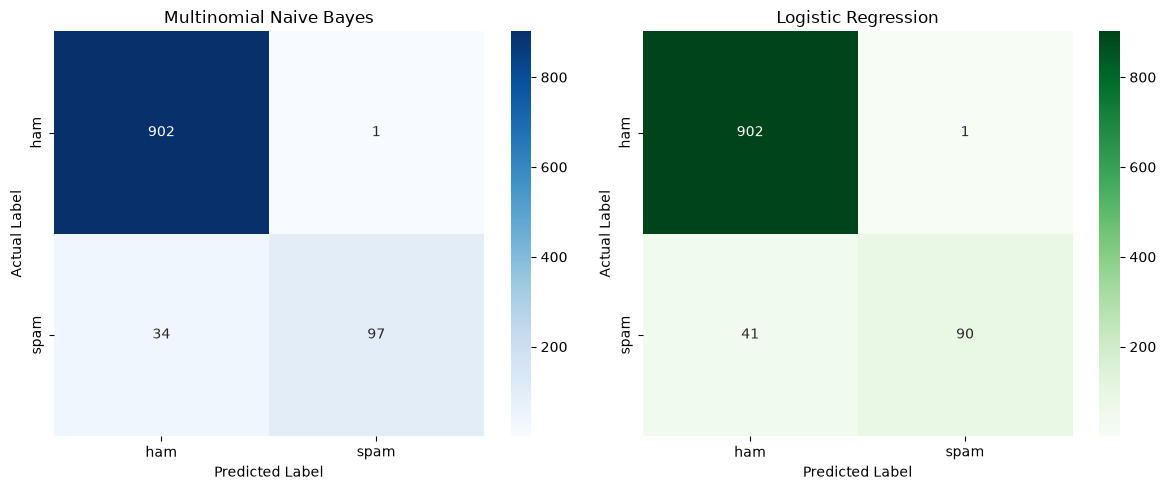

In [12]:
#Calculate confusion matrices for both models
nb_cm = confusion_matrix(y_test, nb_predictions, labels=["ham", "spam"])
lr_cm = confusion_matrix(y_test, lr_predictions, labels=["ham", "spam"])


#Create a figure for both confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


#Display the Naive Bayes confusion matrix
sns.heatmap(
    nb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["ham", "spam"],
    yticklabels=["ham", "spam"],
    ax=axes[0]
)

axes[0].set_title("Multinomial Naive Bayes")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")


#Display the Logistic Regression confusion matrix
sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["ham", "spam"],
    yticklabels=["ham", "spam"],
    ax=axes[1]
)

axes[1].set_title("Logistic Regression")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")


#Display both confusion matrices
plt.tight_layout()
plt.show()

### Confusion Matrix Analysis

The confusion matrices provide a more detailed understanding of how the two classification models performed.

**Multinomial Naive Bayes:**

- Correctly classified 902 legitimate messages.
- Correctly identified 97 spam messages.
- Incorrectly classified 1 legitimate message as spam.
- Failed to identify 34 spam messages.

**Logistic Regression:**

- Correctly classified 902 legitimate messages.
- Correctly identified 90 spam messages.
- Incorrectly classified 1 legitimate message as spam.
- Failed to identify 41 spam messages.

**Conclusion:**

Multinomial Naive Bayes performed better because it identified more spam messages and missed fewer spam messages than Logistic Regression.

Both models performed equally well when identifying legitimate messages. However, Naive Bayes achieved better spam detection performance.

## 10. Project Conclusion

This project successfully developed a machine learning model to classify text messages as spam or ham using Natural Language Processing techniques.

The SMS Spam Collection dataset was cleaned and prepared by removing unnecessary columns, missing values and duplicate records.

Text preprocessing was performed by converting messages to lowercase, removing punctuation and numbers, and eliminating common English stopwords.

TF-IDF was used to transform the cleaned messages into numerical features that could be understood by machine learning algorithms.

Two classification models were trained and evaluated:

- Multinomial Naive Bayes
- Logistic Regression

Multinomial Naive Bayes achieved the best overall performance, with an accuracy of 96.62%, precision of 98.98%, recall of 74.05% and an F1-score of 84.72%.

The results showed that Multinomial Naive Bayes identified more spam messages than Logistic Regression.

This project demonstrated how Natural Language Processing and machine learning can be used to identify unwanted messages. It also highlighted the importance of evaluating classification models using multiple performance metrics rather than relying on accuracy alone.

**Final Model Selection:** Multinomial Naive Bayes.